# Appendix C — Solutions to the Exercises

This appendix collects the solutions of the exercises, chapter by chapter. It grows as the book grows: each new chapter adds its own section.

**How to use it.** Try the exercise first, then read the hint in the chapter, and only then look here. For the manual exercises the solution is written out in full. For the computational exercises the solution is a complete, executable piece of code, followed by a short discussion of what the output shows; there are many correct ways to write such code, and yours may differ.

**A note on the code.** Each solution lives in a function (`solution_1_6()`, and so on), so that the cells do not overwrite each other's variables. The function names match the exercise numbers.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

# Same plotting style and color-blind-safe palette as in the chapters
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## C.1 Chapter 1

### Manual exercises

**Solution 1.1 — Name the problem.**

| Task | Paradigm | Type |
|---|---|---|
| (a) tomorrow's electricity consumption | supervised | regression (the target is a real number) |
| (b) grouping customers without predefined groups | unsupervised | clustering (Chapter 12) |
| (c) spam or not spam | supervised | classification (two classes) |
| (d) learning a game by self-play, from wins and losses | reinforcement learning | the wins and losses are the reward signal (Chapter 22) |
| (e) reducing 1000 measurements to 10 numbers | unsupervised | dimensionality reduction (Chapter 13) |

**Solution 1.2 — Shapes.**
(a) $\mathbf{X} \in \mathbb{R}^{200 \times 5}$ and $\mathbf{y} \in \mathbb{R}^{200}$.
(b) The intercept column adds one column: $200 \times 6$.
(c) $\mathbf{X}^\top\mathbf{X}$ is $d \times d$, that is $5 \times 5$ (and $6 \times 6$ for the design matrix with the intercept). Its size depends on the number of features, not on the number of samples.
(d) Each entry of $\mathbf{X}\mathbf{w}$ is the dot product of a row of $\mathbf{X}$ with $\mathbf{w}$:

$$
\mathbf{X}\mathbf{w} = \begin{pmatrix} 1\cdot 1 + 2\cdot(-1) \\ 3\cdot 1 + 4\cdot(-1) \\ 5\cdot 1 + 6\cdot(-1) \end{pmatrix} = \begin{pmatrix} -1 \\ -1 \\ -1 \end{pmatrix}.
$$

The $i$-th entry is the prediction of the linear model $f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x}$ for the $i$-th sample; here, the first feature minus the second.

**Solution 1.3 — Least squares by hand.** The points are $(0,2)$, $(1,2)$, $(2,5)$.

(a) $\mathbf{X} = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \end{pmatrix}$, $\mathbf{y} = \begin{pmatrix} 2 \\ 2 \\ 5 \end{pmatrix}$. Then $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 3 & 3 \\ 3 & 5 \end{pmatrix}$ and $\mathbf{X}^\top\mathbf{y} = \begin{pmatrix} 9 \\ 12 \end{pmatrix}$. With $\det = 6$,

$$
\hat{\mathbf{w}} = \frac{1}{6}\begin{pmatrix} 5 & -3 \\ -3 & 3 \end{pmatrix}\begin{pmatrix} 9 \\ 12 \end{pmatrix}
= \frac{1}{6}\begin{pmatrix} 9 \\ 9 \end{pmatrix} = \begin{pmatrix} 3/2 \\ 3/2 \end{pmatrix},
$$

so the line is $\hat{y} = \tfrac32 + \tfrac32 x$.

(b) $\hat{\mathbf{y}} = (1.5,\ 3,\ 4.5)^\top$, hence $\mathbf{r} = \mathbf{y} - \hat{\mathbf{y}} = (0.5,\ -1,\ 0.5)^\top$. Then $\sum_i r_i = 0$ and $\mathbf{r}\cdot(0,1,2) = 0 - 1 + 1 = 0$: $\mathbf{X}^\top\mathbf{r} = \mathbf{0}$.

(c) $\text{MSE} = \frac{0.25 + 1 + 0.25}{3} = 0.5$. The mean of $\mathbf{y}$ is $3$ and $\sum_i (y_i - \bar y)^2 = 1 + 1 + 4 = 6$, so $R^2 = 1 - \frac{1.5}{6} = 0.75$.

**Solution 1.4 — Derive it yourself.**
(a) $L(w) = \sum_i (y_i - w x_i)^2$, so $L'(w) = -2\sum_i x_i (y_i - w x_i)$. Setting $L'(w) = 0$ gives $\sum_i x_i y_i = w \sum_i x_i^2$, that is

$$
\hat{w} = \frac{\sum_i x_i y_i}{\sum_i x_i^2}.
$$

(b) With a single column $\mathbf{x} = (x_1, \dots, x_n)^\top$ as the data matrix, $\mathbf{X}^\top\mathbf{X} = \mathbf{x}^\top\mathbf{x} = \sum_i x_i^2$ (a $1\times 1$ matrix) and $\mathbf{X}^\top\mathbf{y} = \sum_i x_i y_i$, so $(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$ is the same ratio.

(c) $L''(w) = 2\sum_i x_i^2$, which is strictly positive unless every $x_i$ is zero. Hence $L$ is strictly convex and $\hat{w}$ is its unique minimizer.

**Solution 1.5 — Which loss, which constant?**
(a) $f(c) = \sum_i (y_i - c)^2$ has $f'(c) = -2\sum_i (y_i - c)$, which vanishes at $c = \frac1n\sum_i y_i$; and $f'' = 2n > 0$. The minimizer is the mean.

(b) Let $g(c) = \sum_i \lvert y_i - c\rvert$, with $n = 2m - 1$ and $m = (n+1)/2$. The function $g$ is piecewise linear. At a point $c$ that is not a data point, $g'(c) = \#\{y_i < c\} - \#\{y_i > c\}$ (each term with $y_i < c$ contributes $+1$, each term with $y_i > c$ contributes $-1$).
- For $c$ between $y_{(m-1)}$ and $y_{(m)}$: $m - 1$ points lie below and $m$ above, so $g' = -1 < 0$.
- For $c$ between $y_{(m)}$ and $y_{(m+1)}$: $m$ points lie below and $m - 1$ above, so $g' = +1 > 0$.

More generally the slope is $2k - n$ when $k$ points lie below $c$, which is negative for $k < m$ and positive for $k \ge m$. So $g$ decreases up to $y_{(m)}$ and increases afterwards: the minimizer is $y_{(m)}$, the median.

(c) Replace $y_n$ by $10^6$. The order of the points is unchanged (it was already the largest, and it only grows), so the **median is unchanged**. The **mean** instead moves by $(10^6 - y_n)/n$, which can be enormous: one outlier drags the optimal constant of the squared loss arbitrarily far. The squared loss is therefore sensitive to outliers (it squares large errors), while the absolute loss is robust. When the data may contain outliers, the choice of loss matters as much as the choice of model.

### Python exercises

**Solution 1.6 — Meet a new data set.**

In [3]:
def solution_1_6():
    from sklearn.datasets import load_wine

    wine = load_wine(as_frame=True)
    X, y = wine.data, wine.target
    print("shape of X:", X.shape)
    print("classes:", dict(zip(wine.target_names.tolist(), np.bincount(y).tolist())))
    print("first five features:", X.columns[:5].tolist())

    stats = X.describe().loc[["mean", "std"]].T
    print("\nmean and standard deviation of each feature:")
    print(stats.round(3).to_string())
    print("\nfeature with the largest standard deviation:", stats["std"].idxmax())

solution_1_6()

shape of X: (178, 13)
classes: {'class_0': 59, 'class_1': 71, 'class_2': 48}
first five features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium']

mean and standard deviation of each feature:
                                 mean      std
alcohol                        13.001    0.812
malic_acid                      2.336    1.117
ash                             2.367    0.274
alcalinity_of_ash              19.495    3.340
magnesium                      99.742   14.282
total_phenols                   2.295    0.626
flavanoids                      2.029    0.999
nonflavanoid_phenols            0.362    0.124
proanthocyanins                 1.591    0.572
color_intensity                 5.058    2.318
hue                             0.957    0.229
od280/od315_of_diluted_wines    2.612    0.710
proline                       746.893  314.907

feature with the largest standard deviation: proline


The Wine data set has 178 samples, 13 features, and 3 classes. The feature `proline` lives on a scale of hundreds (its mean is in the 700s and its standard deviation above 300), while most other features are of order 1 to 100 and some are below 1. In a distance-based method such as k-NN, `proline` would dominate the Euclidean distance and the other features would barely matter: **standardize the features** first (Section 1.8).

**Solution 1.7 — A line on Iris.**

normal equations: [-0.36308  0.41576]
lstsq           : [-0.36308  0.41576]
scikit-learn    : [-0.36308  0.41576]
all agree: True

MSE = 0.0421 | baseline MSE = 0.5771 | R^2 = 0.9271


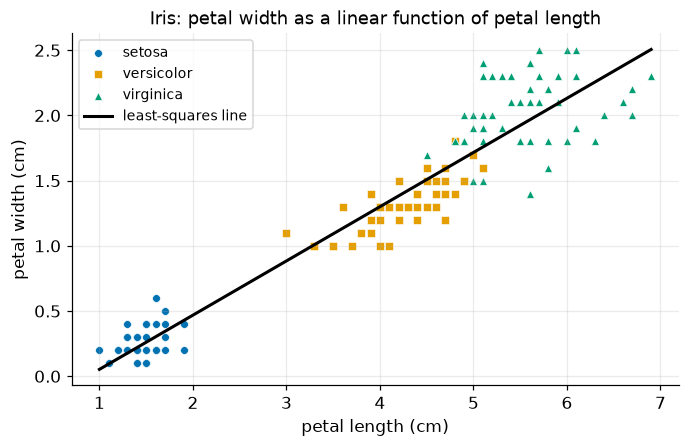

In [4]:
def solution_1_7():
    from sklearn.datasets import load_iris
    from sklearn.linear_model import LinearRegression

    iris = load_iris(as_frame=True)
    x = iris.data["petal length (cm)"].to_numpy()
    t = iris.data["petal width (cm)"].to_numpy()
    A = np.column_stack([np.ones_like(x), x])

    # (a) three ways to the same answer
    w_normal = np.linalg.solve(A.T @ A, A.T @ t)
    w_lstsq = np.linalg.lstsq(A, t, rcond=None)[0]
    lr = LinearRegression().fit(x.reshape(-1, 1), t)
    w_sk = np.array([lr.intercept_, lr.coef_[0]])
    print("normal equations:", w_normal.round(5))
    print("lstsq           :", w_lstsq.round(5))
    print("scikit-learn    :", w_sk.round(5))
    print("all agree:", np.allclose(w_normal, w_lstsq) and np.allclose(w_normal, w_sk))

    # (b) error, baseline, R^2
    t_hat = A @ w_normal
    mse = np.mean((t - t_hat) ** 2)
    mse_base = np.mean((t - t.mean()) ** 2)
    r2 = 1 - np.sum((t - t_hat) ** 2) / np.sum((t - t.mean()) ** 2)
    print(f"\nMSE = {mse:.4f} | baseline MSE = {mse_base:.4f} | R^2 = {r2:.4f}")

    # (c) plot
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    species = iris.target.to_numpy()
    for k, (name, color, marker) in enumerate(zip(iris.target_names, [BLUE, ORANGE, GREEN], ["o", "s", "^"])):
        ax.scatter(x[species == k], t[species == k], s=26, color=color, marker=marker,
                   edgecolor="white", linewidth=0.4, label=name)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, w_normal[0] + w_normal[1] * xs, color="black", linewidth=2, label="least-squares line")
    ax.set_xlabel("petal length (cm)")
    ax.set_ylabel("petal width (cm)")
    ax.set_title("Iris: petal width as a linear function of petal length")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

solution_1_7()

The three methods agree to numerical precision. The line explains more than 90% of the variance of the petal width (compare the MSE with the baseline MSE, and read the $R^2$): on this data set the two petal measurements are strongly linearly related. Note that the cloud is not homogeneous across species, and the line is a compromise between the three groups.

**Solution 1.8 — Does scaling matter?**

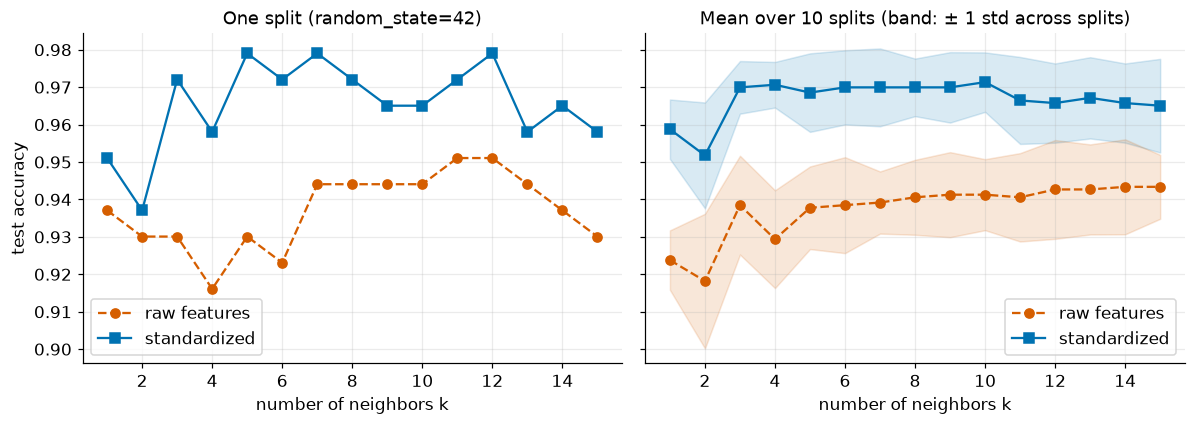

mean accuracy gain from scaling: 0.029
fraction of (split, k) pairs where scaling is at least as good: 1.000
fraction where scaling is strictly better: 0.987


In [5]:
def solution_1_8():
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True, as_frame=True)
    ks = np.arange(1, 16)

    def test_accuracies(seed):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
        raw = [KNeighborsClassifier(k).fit(X_tr, y_tr).score(X_te, y_te) for k in ks]
        scaled = [make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(X_tr, y_tr).score(X_te, y_te)
                  for k in ks]
        return raw, scaled

    # the split of Section 1.8 (random_state = SEED)
    raw_1, scaled_1 = test_accuracies(SEED)
    # ten different splits
    seeds = range(10)
    all_raw, all_scaled = map(np.array, zip(*(test_accuracies(s) for s in seeds)))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    axes[0].plot(ks, raw_1, "o--", color=VERMILION, label="raw features")
    axes[0].plot(ks, scaled_1, "s-", color=BLUE, label="standardized")
    axes[0].set_title(f"One split (random_state={SEED})")
    axes[1].plot(ks, all_raw.mean(axis=0), "o--", color=VERMILION, label="raw features")
    axes[1].plot(ks, all_scaled.mean(axis=0), "s-", color=BLUE, label="standardized")
    axes[1].fill_between(ks, all_scaled.mean(0) - all_scaled.std(0), all_scaled.mean(0) + all_scaled.std(0),
                         color=BLUE, alpha=0.15)
    axes[1].fill_between(ks, all_raw.mean(0) - all_raw.std(0), all_raw.mean(0) + all_raw.std(0),
                         color=VERMILION, alpha=0.15)
    axes[1].set_title("Mean over 10 splits (band: ± 1 std across splits)")
    for ax in axes:
        ax.set_xlabel("number of neighbors k")
        ax.legend()
    axes[0].set_ylabel("test accuracy")
    fig.tight_layout()
    plt.show()

    diff = all_scaled - all_raw                      # shape (10 splits, 15 values of k)
    print(f"mean accuracy gain from scaling: {diff.mean():.3f}")
    print(f"fraction of (split, k) pairs where scaling is at least as good: {(diff >= 0).mean():.3f}")
    print(f"fraction where scaling is strictly better: {(diff > 0).mean():.3f}")

solution_1_8()

The conclusion is stable. Averaged over the ten splits, standardized features give a higher test accuracy for essentially every $k$ (the gain is about three percentage points in our run), and the printed fractions show that scaling was never worse and almost always strictly better across all the (split, $k$) pairs. A single split would have been enough to see the effect here, but *only* repeating the experiment lets us say that the conclusion does not depend on the lucky choice of one split. This habit, repeating the evaluation on several splits, is formalized as cross-validation in Chapter 5.

**Solution 1.9 — Your own overfitting experiment.**

In [6]:
def solution_1_9():
    from numpy.polynomial import polynomial as P
    from sklearn.datasets import load_diabetes
    from sklearn.model_selection import train_test_split

    d = load_diabetes(as_frame=True, scaled=False)
    target = d.target.to_numpy()
    MAX_DEG, N_SPLITS = 8, 100

    def median_test_errors(z, n_train):
        errs = np.zeros((N_SPLITS, MAX_DEG + 1))
        for s in range(N_SPLITS):
            z_tr, z_te, y_tr, y_te = train_test_split(z, target, train_size=n_train, random_state=s)
            for degree in range(MAX_DEG + 1):
                coef = P.polyfit(z_tr, y_tr, degree)
                errs[s, degree] = np.mean((y_te - P.polyval(z_te, coef)) ** 2)
        return np.median(errs, axis=0)

    rows = []
    for feature in ["bp", "s5"]:
        f = d.data[feature].to_numpy()
        z = (f - f.mean()) / f.std()
        for n_train in [30, 100, 300]:
            med = median_test_errors(z, n_train)
            rows.append({"feature": feature, "training size": n_train,
                         "best degree": int(med.argmin()),
                         "test MSE at best degree": round(float(med.min()), 0),
                         "test MSE at degree 1 (a line)": round(float(med[1]), 0),
                         "test MSE at degree 0 (baseline)": round(float(med[0]), 0)})
    print(pd.DataFrame(rows).to_string(index=False))

solution_1_9()

feature  training size  best degree  test MSE at best degree  test MSE at degree 1 (a line)  test MSE at degree 0 (baseline)
     bp             30            1                   5037.0                         5037.0                           6056.0
     bp            100            1                   4874.0                         4874.0                           5982.0
     bp            300            4                   4782.0                         4785.0                           5891.0
     s5             30            1                   4274.0                         4274.0                           6056.0
     s5            100            3                   4053.0                         4126.0                           5982.0
     s5            300            3                   3914.0                         4047.0                           5891.0


In the table, the **best degree does not decrease as the training set grows**, and it tends to increase: with 30 patients a straight line is the best choice for both features, while with 300 patients a slightly more flexible curve is preferred. The reason is that the variance of a flexible model comes from having too few samples to pin down its many coefficients; as $n$ grows this variance shrinks, and the best compromise moves towards more flexibility. Note also that the gain of the best degree over a straight line is small (a few percent at most, and nil for `bp` with 100 or fewer patients): the relationship between a single feature and the target is weak and almost linear, so there is little to gain from flexibility, and the errors for neighboring degrees are close. Every model, however, is clearly better than the baseline (degree 0). The idea that **the right complexity depends on the amount of data** returns in Chapters 3 and 4.

**Solution 1.10 — When $\mathbf{X}^\top\mathbf{X}$ is singular.**

In [7]:
def solution_1_10():
    from sklearn.datasets import load_diabetes

    d = load_diabetes(as_frame=True, scaled=False)
    bmi, target = d.data["bmi"].to_numpy(), d.target.to_numpy()
    A1 = np.column_stack([np.ones_like(bmi), bmi])            # intercept + bmi
    A2 = np.column_stack([np.ones_like(bmi), bmi, bmi])       # intercept + bmi + a duplicate of bmi

    # (a) rank and conditioning
    print("rank of A1:", np.linalg.matrix_rank(A1), "| rank of A2:", np.linalg.matrix_rank(A2),
          "(A2 has 3 columns but only 2 independent ones)")
    print(f"condition number of A1^T A1: {np.linalg.cond(A1.T @ A1):.3g}")
    print(f"condition number of A2^T A2: {np.linalg.cond(A2.T @ A2):.3g}")

    # (b) the normal equations
    try:
        w_solve = np.linalg.solve(A2.T @ A2, A2.T @ target)
        print("np.linalg.solve returned (numerically meaningless):", w_solve)
    except np.linalg.LinAlgError as err:
        print("np.linalg.solve raised LinAlgError:", err)

    # (c) lstsq
    w2 = np.linalg.lstsq(A2, target, rcond=None)[0]
    w1 = np.linalg.lstsq(A1, target, rcond=None)[0]
    print("\nlstsq on A2:", w2.round(4), "| norm:", round(float(np.linalg.norm(w2)), 4))
    print("lstsq on A1:", w1.round(4))
    print("same predictions with and without the duplicate column:", np.allclose(A2 @ w2, A1 @ w1))

    # (d) other solutions with the same predictions
    candidates = {"(w1, 0)": np.array([w1[0], w1[1], 0.0]),
                  "(w1/2, w1/2)  [what lstsq picks]": np.array([w1[0], w1[1] / 2, w1[1] / 2]),
                  "(3 w1/4, w1/4)": np.array([w1[0], 0.75 * w1[1], 0.25 * w1[1]])}
    print("\nweights giving exactly the same predictions, and their norms:")
    for name, w in candidates.items():
        print(f"  {name:<36} predictions equal: {np.allclose(A2 @ w, A1 @ w1)} | norm = {np.linalg.norm(w):.4f}")

solution_1_10()

rank of A1: 2 | rank of A2: 2 (A2 has 3 columns but only 2 independent ones)
condition number of A1^T A1: 2.63e+04
condition number of A2^T A2: inf
np.linalg.solve raised LinAlgError: Singular matrix

lstsq on A2: [-117.7734    5.1166    5.1166] | norm: 117.9954
lstsq on A1: [-117.7734   10.2331]
same predictions with and without the duplicate column: True

weights giving exactly the same predictions, and their norms:
  (w1, 0)                              predictions equal: True | norm = 118.2171
  (w1/2, w1/2)  [what lstsq picks]     predictions equal: True | norm = 117.9954
  (3 w1/4, w1/4)                       predictions equal: True | norm = 118.0509


(a) The matrix $\mathbf{A}_2$ has three columns but rank 2, because the third column equals the second. Consequently $\mathbf{A}_2^\top\mathbf{A}_2$ is singular, and its condition number is astronomically large (of the order of the inverse of machine precision, or beyond), while that of $\mathbf{A}_1^\top\mathbf{A}_1$ is moderate.

(b) The normal equations no longer have a unique solution. Depending on rounding errors, `np.linalg.solve` either raises a `LinAlgError` ("Singular matrix") or returns meaningless numbers; you must not rely on either behavior.

(c) `np.linalg.lstsq` works through the SVD and returns the solution of **minimum norm** among all least-squares solutions: it splits the coefficient of `bmi` equally between the two identical columns. The predictions are exactly those of the model that uses `bmi` once.

(d) In terms of the column space: adding a column that is already a linear combination of the others does not enlarge the column space, so the projection $\hat{\mathbf{y}}$ is the same. What changes is the *parametrization*: infinitely many weight vectors $(w_0, a, b)$ with $a + b = w_1$ produce the same $\hat{\mathbf{y}}$, and the normal equations are underdetermined. Ranking them by their norm, as `lstsq` does, picks one; **regularization** (Chapter 6) will do something similar in a principled way and will also make the problem well-conditioned.